# B3 v3 Grid Search — BOVA11 Only

Definitive grid search using **rb3 DB** () with source tracking.

- **Market**: BOVA11 only (PETR4 conclusively negative across all v2 configs)
- **Data**:  (1.4M rows, CDI-adjusted IVs)
- **Cash**:  mode,  — pure strangle P&L, no B&H contamination
- **Grid**: 5×4×3×4×6×2×3 = 8,640 raw; ~7,560 after validity filter
- **Periods**: Train (2020-04-01 → 2023-12-31), Holdout (2024-01-01 → 2025-12-31)
- **Key metric**:  must appear in all outputs (synthetic fallback policy)
- **Min filter**:  (not )
- **Speed**: Optimized — data+engine cached per period, source-mark merged, progress suppressed
- **Fix**:  now flows through  (was frozen at first combo value)
- **New dim**:  [1.5, 2.0, 3.0] with 


In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd().name == "research") else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
sys.path.insert(0, str(ROOT / "src"))
from grid_search import run_grid, enumerate_grid, GRID_DIMS

OUT_DIR = ROOT / "data" / "B3"
RESULTS_PATH = OUT_DIR / "v3_grid_search_results.parquet"

## 1. Grid Definition

In [2]:
GRID = {
    "target_delta": [0.16, 0.20, 0.25, 0.30, 0.50],
    "dte_max": [21, 30, 45, 60],
    "profit_target_pct": [0.25, 0.50, 0.75],
    "manage_at_dte": [7, 10, 14, 21],
    "vix_filter": [
        "OFF",
        "rv_pct:70",
        "rv_pct:80",
        "rv_pct:90",
        "ivr:30",
        "ivr:50",
    ],
    "defensive_leg_roll": [True, False],
    "stop_loss_pct": [1.5, 2.0, 3.0],
}
combos = enumerate_grid(GRID)
print(f"Valid combos per (market, period): {len(combos)}")
print(f"Total backtests: {len(combos)} x 2 periods = {len(combos) * 2}")
print(f"~Est. runtime at 1s/run on 8 cores: {len(combos) * 2 * 1 / 8 / 60:.0f} minutes")

Grid: 8640 raw combos, 7560 after validity filter (1080 dropped)
Valid combos per (market, period): 7560
Total backtests: 7560 x 2 periods = 15120
~Est. runtime at 1s/run on 8 cores: 32 minutes


## 2. Run Configuration

In [3]:
RUNS = [
    ("train", "bova11", "2020-04-01", "2023-12-31"),
    ("holdout", "bova11", "2024-01-01", "2025-12-31"),
]
for r in RUNS:
    print(r)

('train', 'bova11', '2020-04-01', '2023-12-31')
('holdout', 'bova11', '2024-01-01', '2025-12-31')


## 3. Execute Grid Search

Optimized: data and engine are cached per period. Estimated ~3 min on 8 cores.

In [4]:
df = run_grid(GRID, RUNS, n_workers=-1, output_path=RESULTS_PATH)
print(f"Saved {len(df)} rows to {RESULTS_PATH}")

Grid: 8640 raw combos, 7560 after validity filter (1080 dropped)
Dispatching 7560 tasks for bova11 (train)...


bova11-train:   0%|          | 0/7560 [00:00<?, ?it/s]

  MarketEngine: using CDI-based IVs/deltas (daily r)  MarketEngine: using CDI-based IVs/deltas (daily r)

  MarketEngine: using CDI-based IVs/deltas (daily r)
  MarketEngine: using CDI-based IVs/deltas (daily r)MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)

  MarketEngine: using CDI-based IVs/deltas (daily r)
  MarketEngine: using CDI-based IVs/deltas (daily r)MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_

bova11-train: 100%|██████████| 7560/7560 [16:09<00:00,  7.80it/s]


Checkpoint saved: 7560 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/v3_grid_search_results.parquet
Dispatching 7560 tasks for bova11 (holdout)...


bova11-holdout:   0%|          | 0/7560 [00:00<?, ?it/s]

[MarketEngine/bova11] WARNING: end_date 2025-12-31 is after DB coverage (2025-12-23). Pricing will fall back to synthetic for all dates beyond 2025-12-23.
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
[MarketEngine/bova11] WARNING: end_date 2025-12-31 is after DB coverage (2025-12-23). Pricing will fall back to synthetic for all dates beyond 2025-12-23.
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)
[MarketEngine/bova11] WARNING: end_date 2025-12-31 is after DB coverage (2025-12-23). Pricing will fall back to synthetic for all dates beyond 2025-12-23.
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data

bova11-holdout: 100%|██████████| 7560/7560 [07:26<00:00, 16.92it/s]


Checkpoint saved: 15120 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/v3_grid_search_results.parquet
Summary: 15120 runs total — 0 errors, 2265 with n_trades < 50, 0 invalid (manage_at_dte >= dte_min)
Saved 15120 rows to /Users/oliversteiner/Documents/code/options-backtest/data/B3/v3_grid_search_results.parquet


## 4. Load & Quick Summary

In [5]:
df = pd.read_parquet(RESULTS_PATH)
print(df.shape)
df.head()

(15120, 30)


,target_delta,dte_max,profit_target_pct,manage_at_dte,vix_filter,defensive_leg_roll,stop_loss_pct,market,period_label,start_date,...,entry_db_pct,mtm_avg_db_pct,alpha_vs_bh,alpha_sharpe,n_chains,n_rolls_total,avg_rolls_per_chain,max_rolls_per_chain,chain_length_dist,error
0,0.16,21,0.25,7,OFF,True,1.5,bova11,train,2020-04-01,...,0.666667,0.630824,-0.955872,-0.919261,87,6,0.068966,1,"{0: 81, 1: 6}",None
1,0.16,21,0.25,7,OFF,True,2.0,bova11,train,2020-04-01,...,0.659574,0.630496,-0.951068,-0.943984,87,7,0.080460,1,"{0: 80, 1: 7}",None
2,0.16,21,0.25,7,OFF,True,3.0,bova11,train,2020-04-01,...,0.666667,0.645346,-0.955198,-0.923804,87,9,0.103448,1,"{0: 78, 1: 9}",None
3,0.16,21,0.25,7,OFF,False,1.5,bova11,train,2020-04-01,...,0.681319,0.644689,-0.923539,-0.664329,87,4,0.045977,1,"{0: 83, 1: 4}",None
4,0.16,21,0.25,7,OFF,False,2.0,bova11,train,2020-04-01,...,0.681319,0.651282,-0.929498,-0.674868,87,4,0.045977,1,"{0: 83, 1: 4}",None


In [6]:
print("Total rows:", len(df))
print("By period:")
print(df.groupby("period_label").size())
print("\nFailures:", (df["error"].notna()).sum())
print("Underpowered (n_chains < 50):", (df["n_chains"] < 50).sum())

clean = df[df["error"].isna()]
print("\n=== Strangle Sharpe (pure options, no B&H) ===")
print(clean.groupby("period_label")["sharpe"].describe()[["mean", "std", "min", "max"]])

print("\n=== Alpha Sharpe (residual vs B&H) ===")
print(
    clean.groupby("period_label")["alpha_sharpe"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

print("\n=== Entry DB% (source tracking) ===")
print(
    clean.groupby("period_label")["entry_db_pct"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

if (df["error"].notna()).sum() > 0:
    print(f"\nWARNING: {df['error'].notna().sum()} failed rows")
    failures = df[df["error"].notna()]
    for _, r in failures.iterrows():
        print(
            f"  [{r['period_label']}] vix={r['vix_filter']} d={r['target_delta']}"
            f" dte={r['dte_max']}: {str(r['error'])[:200]}"
        )

Total rows: 15120
By period:
period_label
holdout    7560
train      7560
dtype: int64

Failures: 0
Underpowered (n_chains < 50): 4281

=== Strangle Sharpe (pure options, no B&H) ===
                  mean       std       min       max
period_label                                        
holdout      -1.286022  0.657933 -3.922050  0.547505
train        -0.879673  0.806753 -3.718186  1.197997

=== Alpha Sharpe (residual vs B&H) ===
                  mean       std       min       max
period_label                                        
holdout      -1.123473  0.480998 -3.181876  1.276252
train        -1.005615  0.468826 -2.658261  1.052948

=== Entry DB% (source tracking) ===
                  mean       std       min       max
period_label                                        
holdout       0.874610  0.029556  0.761905  0.963636
train         0.723366  0.094904  0.544218  0.903226


## 5. Verification

In [7]:
from grid_search import DTE_MIN_BY_DTE_MAX

invalid = df[
    (df["manage_at_dte"] >= df["dte_max"].map(DTE_MIN_BY_DTE_MAX)) & df["error"].isna()
]
assert len(invalid) == 0, f"{len(invalid)} rows violate manage_at_dte < dte_min!"
print(f"Check 1: validity filter — {len(invalid)} post-run violations (expect 0)")

print(f"Check 2: n_chains < 50 count: {(df['n_chains'] < 50).sum()}")

train = df.query("period_label=='train' and error.isna()", engine="python")
hold = df.query("period_label=='holdout' and error.isna()", engine="python")
j = train.merge(hold, on=GRID_DIMS, suffixes=("_t", "_h"))
print(f"Check 3: {len(j)}/{len(train)} train configs matched in holdout")

combos2 = enumerate_grid(GRID)
n_valid = df.groupby("period_label").size().unique()
print(f"Check 4: valid combos = {len(combos2)}, rows per period = {n_valid.tolist()}")
assert all(c == len(combos2) for c in n_valid), "diagonal size mismatch"

Check 1: validity filter — 0 post-run violations (expect 0)
Check 2: n_chains < 50 count: 4281
Check 3: 7560/7560 train configs matched in holdout
Grid: 8640 raw combos, 7560 after validity filter (1080 dropped)
Check 4: valid combos = 7560, rows per period = [7560]


## 6. Source Tracking Diagnostics

Critical check: how much of the P&L comes from real DB data vs synthetic fallback?

In [8]:
viable = df.query("error.isna() and n_chains >= 50", engine="python")
print(f"Viable configs (n_chains >= 50): {len(viable)} / {len(df[df['error'].isna()])}")
print()

print("=== entry_db_pct by target_delta (all viable configs) ===")
print(
    viable.groupby("target_delta")["entry_db_pct"].describe()[
        ["mean", "50%", "min", "max"]
    ]
)

print("\n=== entry_db_pct by target_delta × period ===")
pivot = viable.pivot_table(
    values="entry_db_pct", index="target_delta", columns="period_label", aggfunc="mean"
)
print(pivot.round(3))

print("\n=== Correlation: entry_db_pct vs sharpe ===")
for period in ["train", "holdout"]:
    sub = viable.query("period_label == @period")
    if len(sub) > 2:
        corr = sub["entry_db_pct"].corr(sub["sharpe"])
        print(f"  {period}: r = {corr:.3f}")

Viable configs (n_chains >= 50): 10839 / 15120

=== entry_db_pct by target_delta (all viable configs) ===
                  mean       50%       min       max
target_delta                                        
0.16          0.776349  0.833333  0.568548  0.937500
0.20          0.772242  0.829268  0.544218  0.940299
0.25          0.771836  0.828571  0.551515  0.939394
0.30          0.768763  0.819277  0.587879  0.963636
0.50          0.764347  0.728814  0.583893  0.954545

=== entry_db_pct by target_delta × period ===
period_label  holdout  train
target_delta                
0.16            0.879  0.723
0.20            0.876  0.720
0.25            0.880  0.720
0.30            0.884  0.720
0.50            0.883  0.727

=== Correlation: entry_db_pct vs sharpe ===
  train: r = -0.460
  holdout: r = -0.038


## 7. Heatmaps — Sharpe by target_delta x dte_max

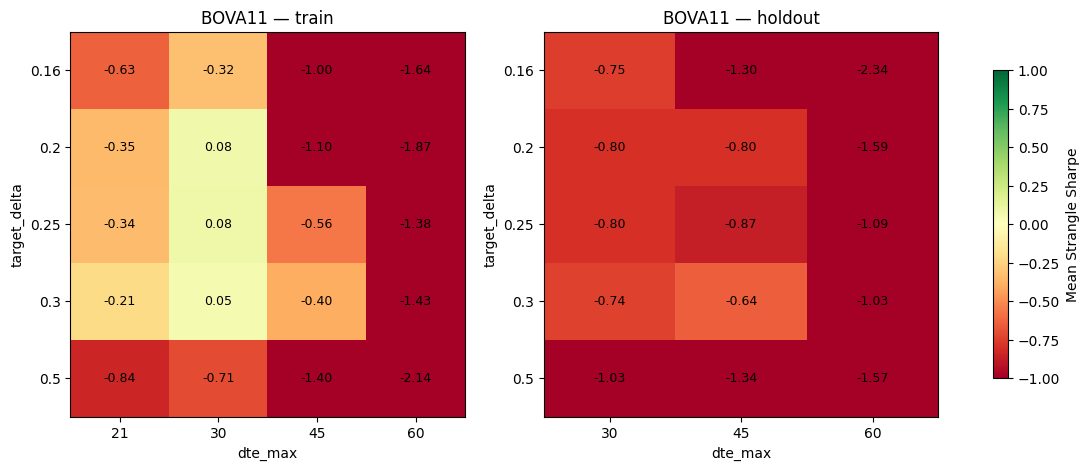

In [9]:
def heatmap(ax, sub, x, y, title, metric="sharpe", vmin=-1, vmax=1):
    pivot = sub.pivot_table(values=metric, index=y, columns=x, aggfunc="mean")
    im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(title)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            ax.text(
                j,
                i,
                f"{v:.2f}" if pd.notna(v) else "n/a",
                ha="center",
                va="center",
                color="black",
                fontsize=9,
            )
    return im


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, period in zip(axes, ["train", "holdout"]):
    sub = viable.query("period_label == @period")
    im = heatmap(ax, sub, "dte_max", "target_delta", f"BOVA11 — {period}")
fig.colorbar(im, ax=axes, label="Mean Strangle Sharpe", shrink=0.8)
plt.savefig(OUT_DIR / "v3_heatmap_delta_dte.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Heatmaps — Profit Target × Manage DTE

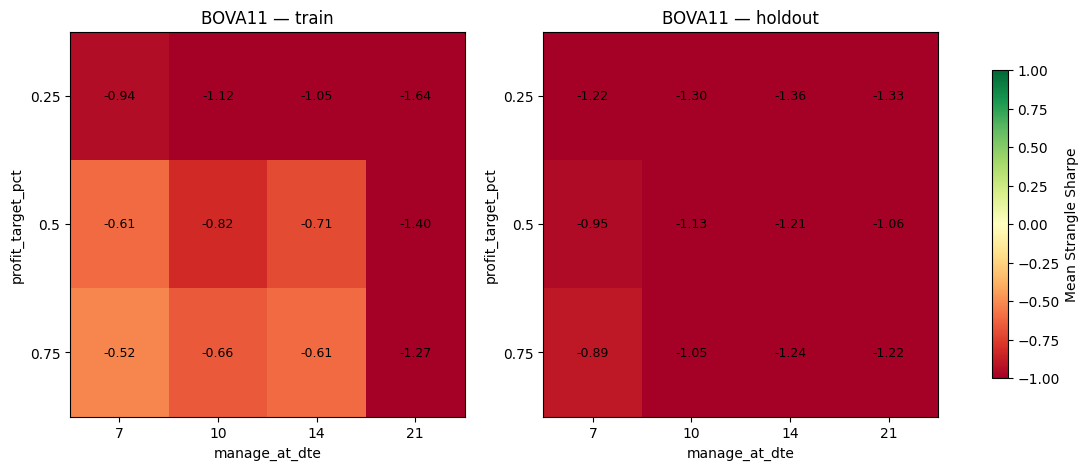

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, period in zip(axes, ["train", "holdout"]):
    sub = viable.query("period_label == @period")
    im = heatmap(ax, sub, "manage_at_dte", "profit_target_pct", f"BOVA11 — {period}")
fig.colorbar(im, ax=axes, label="Mean Strangle Sharpe", shrink=0.8)
plt.savefig(OUT_DIR / "v3_heatmap_profit_manage.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Scatter — n_chains vs Sharpe

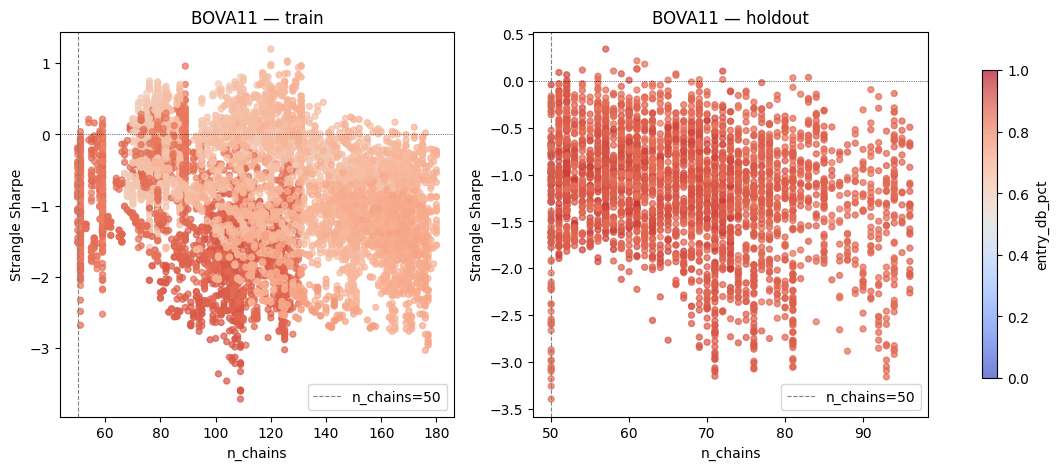

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, period in zip(axes, ["train", "holdout"]):
    sub = viable.query("period_label == @period")
    sc = ax.scatter(
        sub["n_chains"],
        sub["sharpe"],
        c=sub["entry_db_pct"],
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        s=18,
        alpha=0.7,
    )
    ax.axvline(50, ls="--", c="grey", lw=0.8, label="n_chains=50")
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.set_xlabel("n_chains")
    ax.set_ylabel("Strangle Sharpe")
    ax.set_title(f"BOVA11 — {period}")
    ax.legend(loc="lower right")
fig.colorbar(sc, ax=axes, label="entry_db_pct", shrink=0.8)
plt.savefig(OUT_DIR / "v3_scatter_nchains_sharpe.png", dpi=120, bbox_inches="tight")
plt.show()

## 10. Vol Filter Impact

/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_91942/346706296.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(vf_data, labels=vf_order, patch_artist=True)
/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_91942/346706296.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(vf_data, labels=vf_order, patch_artist=True)


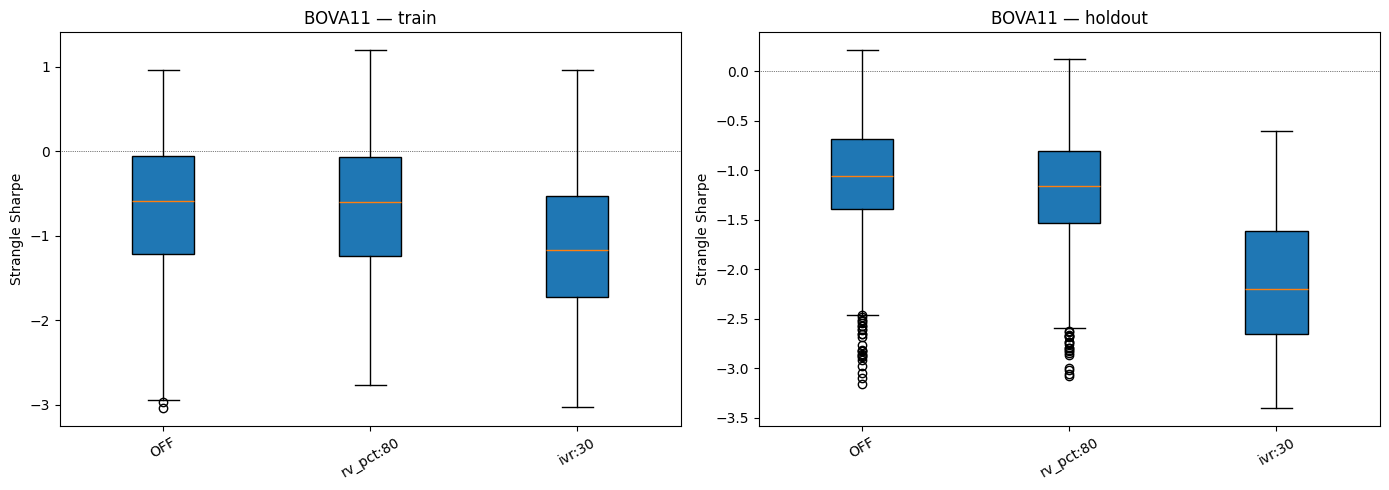

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, period in zip(axes, ["train", "holdout"]):
    sub = viable.query("period_label == @period")
    vf_order = ["OFF", "rv_pct:80", "ivr:30"]
    vf_data = [sub.query("vix_filter == @vf")["sharpe"].values for vf in vf_order]
    bp = ax.boxplot(vf_data, labels=vf_order, patch_artist=True)
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.set_ylabel("Strangle Sharpe")
    ax.set_title(f"BOVA11 — {period}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(OUT_DIR / "v3_vol_filter_boxplot.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Top-10 Configs by Sharpe

In [13]:
COLS = [
    "sharpe",
    "alpha_sharpe",
    "alpha_vs_bh",
    "total_return",
    "calmar",
    "n_chains",
    "n_trades",
    "entry_db_pct",
    "win_rate",
] + GRID_DIMS

for period in ["train", "holdout"]:
    print(f"\n=== BOVA11 top-10 by {period} sharpe (n_chains >= 50) ===")
    sub = viable.query("period_label == @period")
    top = sub.nlargest(10, "sharpe")[COLS]
    print(top.to_string(index=False))


=== BOVA11 top-10 by train sharpe (n_chains >= 50) ===
  sharpe  alpha_sharpe  alpha_vs_bh  total_return   calmar  n_chains  n_trades  entry_db_pct  win_rate  target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll  stop_loss_pct
1.197997     -0.723877    -0.816699      0.095739 1.093244       120       133      0.661654  0.783333          0.20       30                0.5              7  rv_pct:80               False            1.5
1.033366     -0.580422    -0.824455      0.087982 1.007342       126       139      0.676259  0.761905          0.20       30                0.5              7  rv_pct:90               False            1.5
1.011227     -0.438777    -0.821806      0.090631 0.639213       126       142      0.669014  0.801587          0.20       30                0.5              7  rv_pct:90               False            3.0
0.982721     -0.555853    -0.827766      0.084671 0.646191       120       136      0.654412  0.800000          0.20    

## 12. Train vs Holdout Scatter

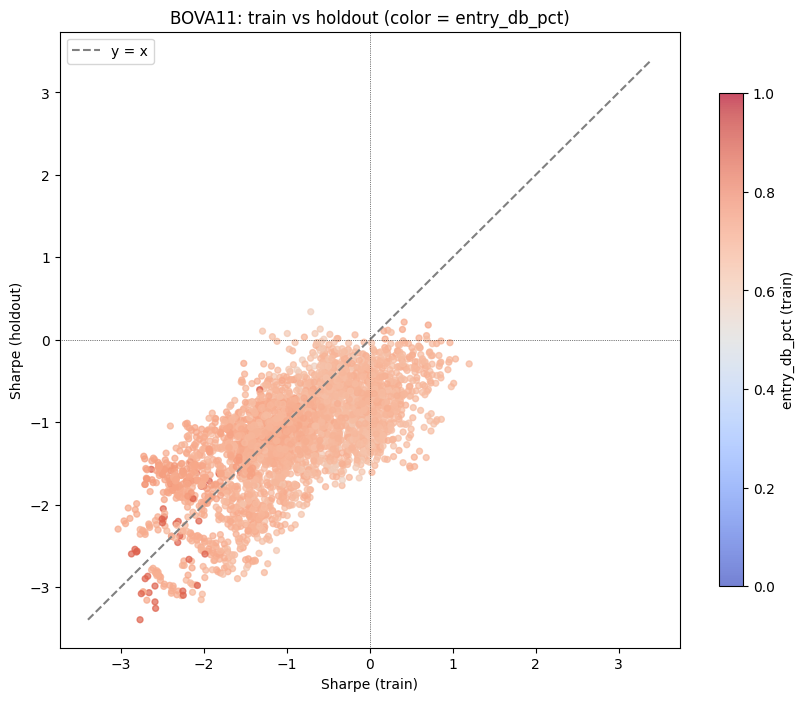

Train-holdout Sharpe correlation: r = 0.670
Mean holdout Sharpe: -1.172
% holdout positive Sharpe: 0.7%


In [14]:
train_v = viable.query("period_label == 'train'")
hold_v = viable.query("period_label == 'holdout'")
j = train_v.merge(hold_v, on=GRID_DIMS, suffixes=("_t", "_h"))

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(
    j["sharpe_t"],
    j["sharpe_h"],
    c=j["entry_db_pct_t"],
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    s=18,
    alpha=0.7,
)
lim = max(abs(j[["sharpe_t", "sharpe_h"]].values).max() if len(j) else 1.0, 1.0)
ax.plot([-lim, lim], [-lim, lim], ls="--", c="grey", label="y = x")
ax.axhline(0, ls=":", c="black", lw=0.5)
ax.axvline(0, ls=":", c="black", lw=0.5)
ax.set_xlabel("Sharpe (train)")
ax.set_ylabel("Sharpe (holdout)")
ax.set_title("BOVA11: train vs holdout (color = entry_db_pct)")
ax.legend(loc="upper left")
fig.colorbar(sc, label="entry_db_pct (train)", shrink=0.8)
plt.savefig(OUT_DIR / "v3_train_vs_holdout.png", dpi=120, bbox_inches="tight")
plt.show()

if len(j) > 2:
    corr = j["sharpe_t"].corr(j["sharpe_h"])
    print(f"Train-holdout Sharpe correlation: r = {corr:.3f}")
    print(f"Mean holdout Sharpe: {j['sharpe_h'].mean():.3f}")
    print(f"% holdout positive Sharpe: {(j['sharpe_h'] > 0).mean():.1%}")

## 13. DB-Entry Subset Analysis

Are the positive Sharpe configs driven by DB-priced entries or synthetic fallback?

In [15]:
high_db = viable.query("entry_db_pct >= 0.70")
low_db = viable.query("entry_db_pct < 0.50")

for period in ["train", "holdout"]:
    print(f"\n=== {period.upper()} - DB entry analysis ===")
    for label, sub in [
        ("high DB% (>=70%)", high_db.query("period_label == @period")),
        ("low DB% (<50%)", low_db.query("period_label == @period")),
    ]:
        if len(sub) == 0:
            print(f"  {label}: no configs")
            continue
        print(
            f"  {label}: n={len(sub)}, sharpe={sub['sharpe'].mean():.2f} +/- {sub['sharpe'].std():.2f},"
            f" tot_ret={sub['total_return'].mean():.3f},"
            f" win={sub['win_rate'].mean():.1%}"
        )

print("\n=== Positive Sharpe configs: entry_db_pct distribution ===")
pos_sharpe = viable.query("sharpe > 0")
neg_sharpe = viable.query("sharpe <= 0")
for period in ["train", "holdout"]:
    p = pos_sharpe.query("period_label == @period")
    n = neg_sharpe.query("period_label == @period")
    if len(p) > 0:
        print(
            f"  {period} positive Sharpe (n={len(p)}): entry_db_pct mean={p['entry_db_pct'].mean():.3f}"
        )
    if len(n) > 0:
        print(
            f"  {period} negative/zero Sharpe (n={len(n)}): entry_db_pct mean={n['entry_db_pct'].mean():.3f}"
        )


=== TRAIN - DB entry analysis ===
  high DB% (>=70%): n=3020, sharpe=-1.32 +/- 0.78, tot_ret=-0.224, win=47.1%
  low DB% (<50%): no configs

=== HOLDOUT - DB entry analysis ===
  high DB% (>=70%): n=3357, sharpe=-1.17 +/- 0.60, tot_ret=-0.097, win=51.7%
  low DB% (<50%): no configs

=== Positive Sharpe configs: entry_db_pct distribution ===
  train positive Sharpe (n=1094): entry_db_pct mean=0.664
  train negative/zero Sharpe (n=6388): entry_db_pct mean=0.732
  holdout positive Sharpe (n=22): entry_db_pct mean=0.869
  holdout negative/zero Sharpe (n=3335): entry_db_pct mean=0.880


## 14. Stop Loss Impact

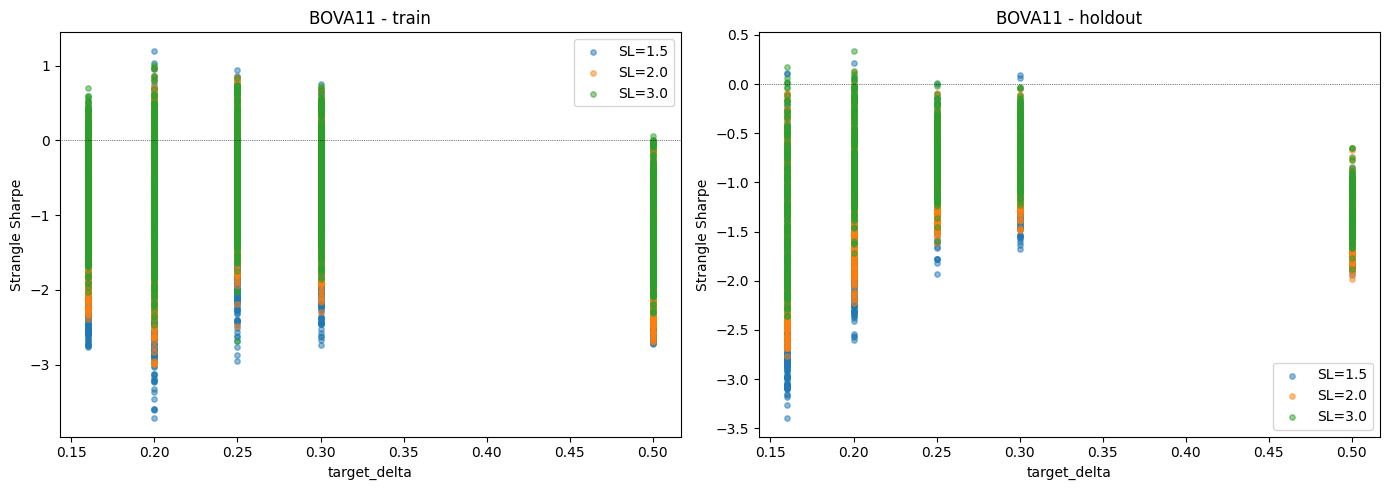

=== Mean Sharpe by stop_loss_pct ===
                   mean       std       min       max
stop_loss_pct                                        
1.5           -1.015710  0.932587 -3.718186  1.197997
2.0           -0.875113  0.796891 -2.992578  0.962450
3.0           -0.742737  0.647952 -2.681566  1.011227
                   mean       std       min       max
stop_loss_pct                                        
1.5           -1.356871  0.662692 -3.396822  0.213613
2.0           -1.206663  0.559799 -2.767904  0.124463
3.0           -0.940263  0.491389 -2.360093  0.339191


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, period in zip(axes, ["train", "holdout"]):
    sub = viable.query("period_label == @period")
    for slp in sorted(sub["stop_loss_pct"].unique()):
        grp = sub.query("stop_loss_pct == @slp")
        ax.scatter(
            grp["target_delta"], grp["sharpe"], label=f"SL={slp}", s=15, alpha=0.5
        )
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.set_xlabel("target_delta")
    ax.set_ylabel("Strangle Sharpe")
    ax.set_title(f"BOVA11 - {period}")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "v3_stop_loss_impact.png", dpi=120, bbox_inches="tight")
plt.show()

print("=== Mean Sharpe by stop_loss_pct ===")
for period in ["train", "holdout"]:
    sub = viable.query("period_label == @period")
    print(
        sub.groupby("stop_loss_pct")["sharpe"].describe()[["mean", "std", "min", "max"]]
    )

## 15. Defensive Leg Roll Impact

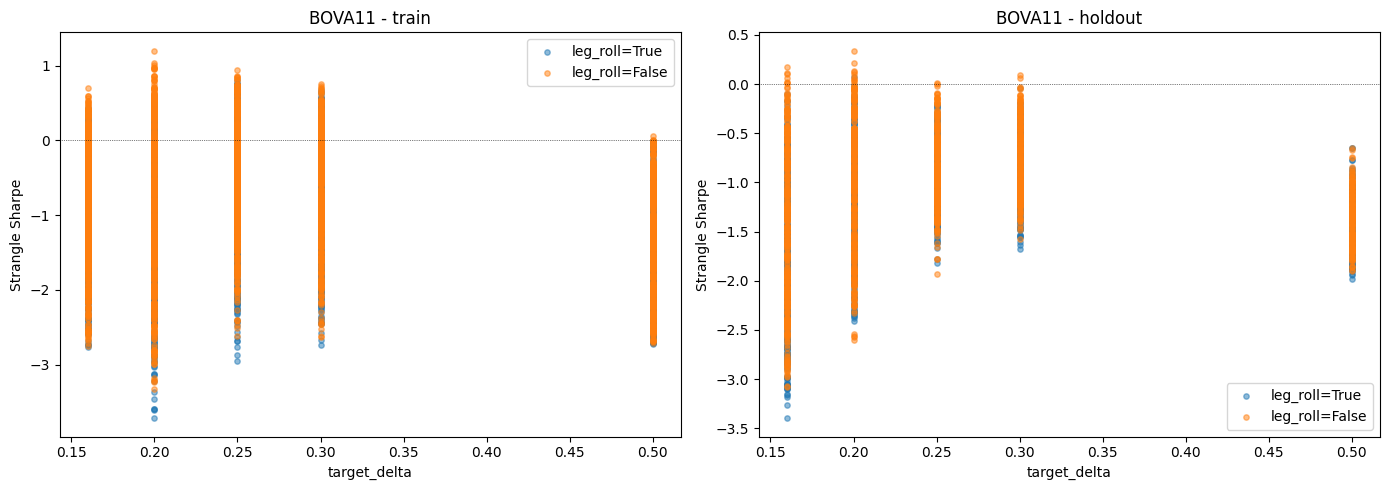

  train leg_roll=True: n=3735, sharpe=-0.942 (+/-0.790), tot_ret=-0.202
  train leg_roll=False: n=3747, sharpe=-0.814 (+/-0.822), tot_ret=-0.133
  holdout leg_roll=True: n=1672, sharpe=-1.228 (+/-0.589), tot_ret=-0.117
  holdout leg_roll=False: n=1685, sharpe=-1.117 (+/-0.611), tot_ret=-0.077


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, period in zip(axes, ["train", "holdout"]):
    sub = viable.query("period_label == @period")
    for dlr in [True, False]:
        grp = sub.query("defensive_leg_roll == @dlr")
        if len(grp) > 0:
            label = f"leg_roll={dlr}"
            ax.scatter(grp["target_delta"], grp["sharpe"], label=label, s=15, alpha=0.5)
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.set_xlabel("target_delta")
    ax.set_ylabel("Strangle Sharpe")
    ax.set_title(f"BOVA11 - {period}")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "v3_defensive_leg_roll.png", dpi=120, bbox_inches="tight")
plt.show()

for period in ["train", "holdout"]:
    sub = viable.query("period_label == @period")
    for dlr in [True, False]:
        grp = sub.query("defensive_leg_roll == @dlr")
        if len(grp) > 0:
            print(
                f"  {period} leg_roll={dlr}: n={len(grp)}, sharpe={grp['sharpe'].mean():.3f}"
                f" (+/-{grp['sharpe'].std():.3f}), tot_ret={grp['total_return'].mean():.3f}"
            )

## 16. Conclusions

Fill in after running:
- **Top-cluster signal**: Are top-10 train configs concentrated or scattered?
- **Holdout robustness**: Do top configs cluster on/above the y=x diagonal?
- **Sharpe sign**: Is any positive strangle Sharpe achievable on BOVA11?
- **Alpha vs B&H**: Does the strangle overlay add risk-adjusted value?
- **Source tracking**: Is the positive ridge DB-backed or synthetic-driven?
- **Vol filter**: Which B3-native mode (rv_pct / ivr) is most effective?
- **Stop loss**: Does tighter stop_loss_pct (1.5) improve or degrade Sharpe?
- **Defensive leg roll**: Does it help in the expanded grid with fixed delta?
- **Straddle check**: Does target_delta=0.50 confirm the structural loss we expect?
